# Sentiment Analysis of MIT AI News Articles
## Exploratory NLP with VADER
Analyzes titles and summaries, not full article bodies. VADER labels are heuristic text-tone estimates; this dataset does not measure public trust.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import re
import string

from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer

In [2]:
nltk.download('vader_lexicon')

Out[2]: False


In [3]:
from pathlib import Path
DATA_PATH = Path("data/MIT_AI_ARTICLES.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../data/MIT_AI_ARTICLES.csv")
df = pd.read_csv(DATA_PATH)
df.head()


Out[3]: 
   Unnamed: 0.1  ...                                                url
0             0  ...  https://news.mit.edu/2025/new-model-predicts-h...
1             1  ...  https://news.mit.edu/2025/researchers-glimpse-...
2             2  ...  https://news.mit.edu/2025/how-ai-could-speed-d...
3             3  ...  https://news.mit.edu/2025/using-generative-ai-...
4             4  ...  https://news.mit.edu/2025/new-way-test-how-wel...

[5 rows x 10 columns]


In [4]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (314, 10)

Columns:
['Unnamed: 0.1', 'Unnamed: 0', 'title', 'author', 'publication_date', 'datetime', 'summary', 'body', 'paper_link', 'url']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 314 entries, 0 to 313
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0.1      314 non-null    int64
 1   Unnamed: 0        314 non-null    int64
 2   title             314 non-null    str  
 3   author            314 non-null    str  
 4   publication_date  314 non-null    str  
 5   datetime          314 non-null    str  
 6   summary           314 non-null    str  
 7   body              314 non-null    str  
 8   paper_link        314 non-null    str  
 9   url               314 non-null    str  
dtypes: int64(2), str(8)
memory usage: 2.2 MB


In [6]:
df.isnull().sum()

Out[6]: 
Unnamed: 0.1        0
Unnamed: 0          0
title               0
author              0
publication_date    0
datetime            0
summary             0
body                0
paper_link          0
url                 0
dtype: int64


In [7]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate titles:", df["title"].duplicated().sum())

print("Duplicate URLs:", df["url"].duplicated().sum())

Duplicate rows: 0
Duplicate titles: 0
Duplicate URLs: 0


In [8]:
# Remove CSV export index columns regardless of pandas header naming.
df = df.loc[:, ~df.columns.str.startswith("Unnamed:")].copy()
df.head()


Out[8]: 
                                               title  ...                                                url
0  A new model predicts how molecules will dissol...  ...  https://news.mit.edu/2025/new-model-predicts-h...
1  Researchers glimpse the inner workings of prot...  ...  https://news.mit.edu/2025/researchers-glimpse-...
2  How AI could speed the development of RNA vacc...  ...  https://news.mit.edu/2025/how-ai-could-speed-d...
3  Using generative AI, researchers design compou...  ...  https://news.mit.edu/2025/using-generative-ai-...
4  A new way to test how well AI systems classify...  ...  https://news.mit.edu/2025/new-way-test-how-wel...

[5 rows x 8 columns]


In [9]:
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce", utc=True)
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.tz_localize(None).dt.to_period("M")
df[["publication_date", "datetime", "year", "month"]].head()


Out[9]: 
  publication_date                  datetime  year    month
0  August 19, 2025 2025-08-19 09:00:00+00:00  2025  2025-08
1  August 18, 2025 2025-08-18 19:00:00+00:00  2025  2025-08
2  August 15, 2025 2025-08-15 09:00:00+00:00  2025  2025-08
3  August 14, 2025 2025-08-14 15:00:00+00:00  2025  2025-08
4  August 13, 2025 2025-08-13 19:00:00+00:00  2025  2025-08


In [10]:
# Preserve punctuation and capitalization for VADER.
df["sentiment_text"] = df["title"].fillna("").str.strip() + ". " + df["summary"].fillna("").str.strip()
# Compatibility name used by the keyword and word-cloud cells below.
df["clean_text"] = df["sentiment_text"]


In [11]:
sia = SentimentIntensityAnalyzer()


In [12]:
# Score each article once; rerun from the top to rebuild df.


In [13]:
sentiment_scores = df["clean_text"].apply(
    sia.polarity_scores
)

sentiment_df = pd.DataFrame(
    sentiment_scores.tolist()
)

sentiment_df.head()

Out[13]: 
     neg    neu    pos  compound
0  0.000  0.912  0.088    0.4215
1  0.000  0.906  0.094    0.4404
2  0.000  0.903  0.097    0.4576
3  0.133  0.737  0.130   -0.2732
4  0.046  0.826  0.128    0.4005


In [14]:
df = pd.concat(
    [df.reset_index(drop=True),
     sentiment_df.reset_index(drop=True)],
    axis=1
)

df.head()

Out[14]: 
                                               title  ...  compound
0  A new model predicts how molecules will dissol...  ...    0.4215
1  Researchers glimpse the inner workings of prot...  ...    0.4404
2  How AI could speed the development of RNA vacc...  ...    0.4576
3  Using generative AI, researchers design compou...  ...   -0.2732
4  A new way to test how well AI systems classify...  ...    0.4005

[5 rows x 16 columns]


In [15]:
def classify_sentiment(score):

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


df["sentiment"] = df["compound"].apply(
    classify_sentiment
)
df[
    ["title", "compound", "sentiment"]
].head(10)

Out[15]: 
                                               title  compound sentiment
0  A new model predicts how molecules will dissol...    0.4215  Positive
1  Researchers glimpse the inner workings of prot...    0.4404  Positive
2  How AI could speed the development of RNA vacc...    0.4576  Positive
3  Using generative AI, researchers design compou...   -0.2732  Negative
4  A new way to test how well AI systems classify...    0.4005  Positive
5            MIT gears up to transform manufacturing    0.0000   Neutral
6  Eco-driving measures could significantly reduc...   -0.2732  Negative
7  School of Architecture and Planning welcomes n...    0.5994  Positive
8  Helping data storage keep up with the AI revol...    0.5267  Positive
9  MIT tool visualizes and edits “physically impo...    0.5574  Positive


In [16]:
validation_sample = df[
    ["title", "summary", "compound", "sentiment"]
].sample(30, random_state=42)

validation_sample

Out[16]: 
                                                 title  ... sentiment
132  Startup’s autonomous drones precisely track wa...  ...   Neutral
33   Using generative AI to help robots jump higher...  ...  Positive
222  Melissa Choi named director of MIT Lincoln Lab...  ...  Positive
57   MIT announces the Initiative for New Manufactu...  ...  Positive
256  Julie Shah named head of the Department of Aer...  ...  Positive
204  Dimitris Bertsimas named vice provost for open...  ...   Neutral
25           AI shapes autonomous underwater “gliders”  ...  Positive
9    MIT tool visualizes and edits “physically impo...  ...  Positive
242             A community collaboration for progress  ...  Negative
224  Eric Evans receives Department of Defense Meda...  ...  Positive
278  Five MIT faculty members take on Cancer Grand ...  ...  Negative
202  MIT researchers use large language models to f...  ...  Negative
238  A technique for more effective multipurpose ro...  ...  Positive
45        

In [17]:
sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(
        ["Positive", "Neutral", "Negative"],
        fill_value=0
    )
)

sentiment_counts

Out[17]: 
sentiment
Positive    237
Neutral      41
Negative     36
Name: count, dtype: int64


In [18]:
sentiment_percent = (
    sentiment_counts /
    sentiment_counts.sum() * 100
)

sentiment_percent

Out[18]: 
sentiment
Positive    75.477707
Neutral     13.057325
Negative    11.464968
Name: count, dtype: float64


<ipython-input-19-2333cf904948>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


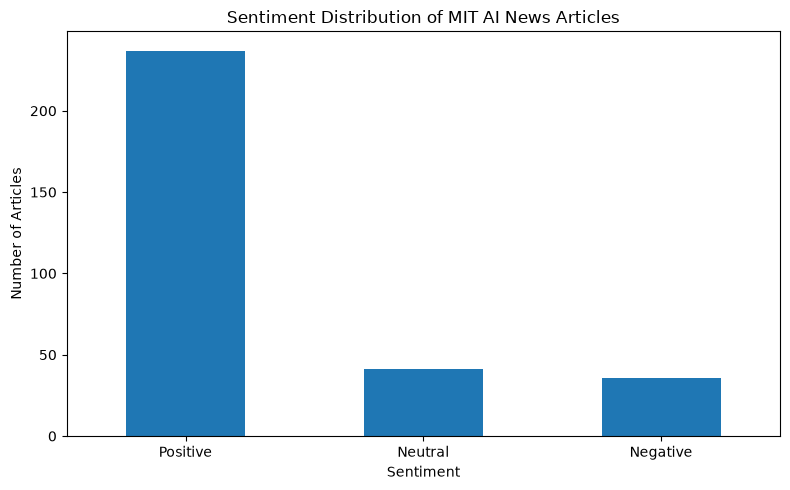

In [19]:
plt.figure(figsize=(8, 5))

sentiment_counts.plot(
    kind="bar"
)

plt.title(
    "Sentiment Distribution of MIT AI News Articles"
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Articles")

plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

<ipython-input-20-de6acd273392>:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


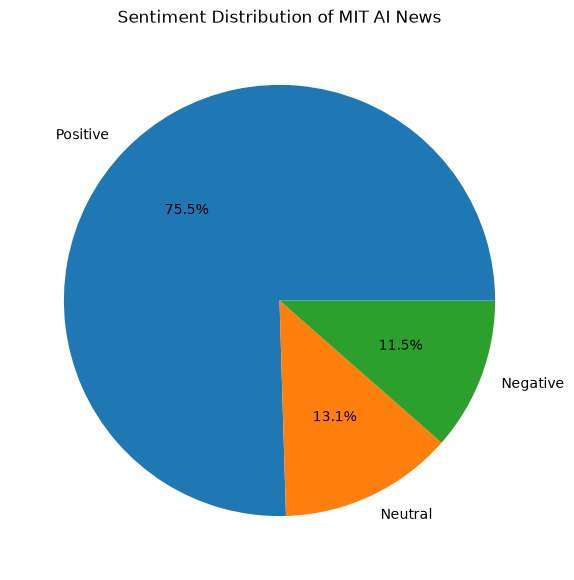

In [20]:
plt.figure(figsize=(7, 7))

sentiment_counts.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title(
    "Sentiment Distribution of MIT AI News"
)

plt.ylabel("")

plt.show()

In [21]:
print(
    "Average sentiment score:",
    round(df["compound"].mean(), 3)
)

print(
    "Median sentiment score:",
    round(df["compound"].median(), 3)
)

Average sentiment score: 0.387
Median sentiment score: 0.44


In [22]:
yearly_sentiment = (
    df.groupby("year")["compound"]
    .mean()
)

yearly_sentiment

Out[22]: 
year
2023    0.054500
2024    0.405870
2025    0.372531
Name: compound, dtype: float64


In [23]:
yearly_stats = df.groupby("year").agg(
    article_count=("compound", "size"),
    mean_sentiment=("compound", "mean"),
    median_sentiment=("compound", "median"),
    std_sentiment=("compound", "std")
)

yearly_stats

Out[23]: 
      article_count  mean_sentiment  median_sentiment  std_sentiment
year                                                                
2023              4        0.054500            0.0386       0.622587
2024            179        0.405870            0.4767       0.388792
2025            131        0.372531            0.4019       0.356250


<ipython-input-24-e626df1e8f99>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


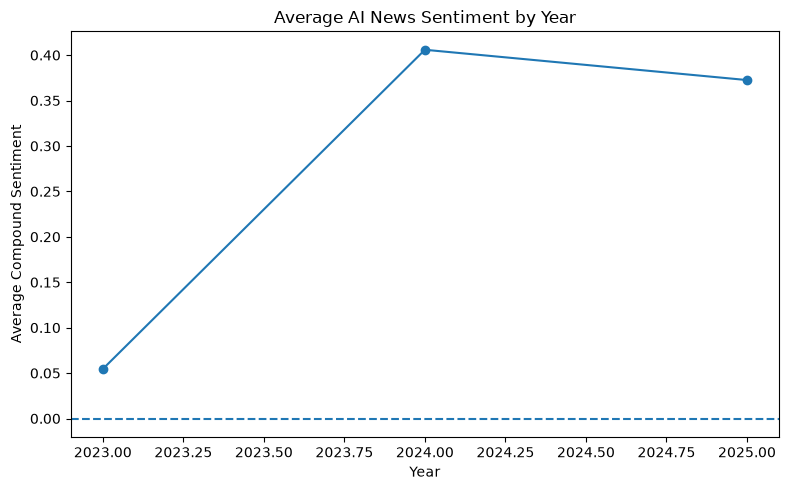

In [24]:
plt.figure(figsize=(8, 5))

yearly_sentiment.plot(
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Average AI News Sentiment by Year"
)

plt.xlabel("Year")
plt.ylabel("Average Compound Sentiment")

plt.tight_layout()

plt.show()

In [25]:
monthly_sentiment = (
    df.groupby("month")["compound"]
    .mean()
)

monthly_sentiment.head()

Out[25]: 
month
2023-12    0.054500
2024-01    0.524500
2024-02    0.125567
2024-03    0.437131
2024-04    0.475753
Freq: M, Name: compound, dtype: float64


In [26]:
monthly_stats = df.groupby("month").agg(
    article_count=("compound", "size"),
    mean_sentiment=("compound", "mean")
)

monthly_stats

Out[26]: 
         article_count  mean_sentiment
month                                 
2023-12              4        0.054500
2024-01             11        0.524500
2024-02             15        0.125567
2024-03             13        0.437131
2024-04             17        0.475753
2024-05             15        0.281847
2024-06             17        0.441282
2024-07             17        0.467206
2024-08             10        0.392900
2024-09             12        0.413850
2024-10             10        0.517110
2024-11             18        0.377900
2024-12             24        0.445279
2025-01             17        0.370229
2025-02             16        0.329663
2025-03             11        0.377518
2025-04             18        0.440433
2025-05             15        0.440087
2025-06             23        0.321417
2025-07             21        0.395314
2025-08             10        0.285710


In [27]:
monthly_sentiment.index = (
    monthly_sentiment
    .index
    .astype(str)
)

<ipython-input-28-276af6f95b97>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


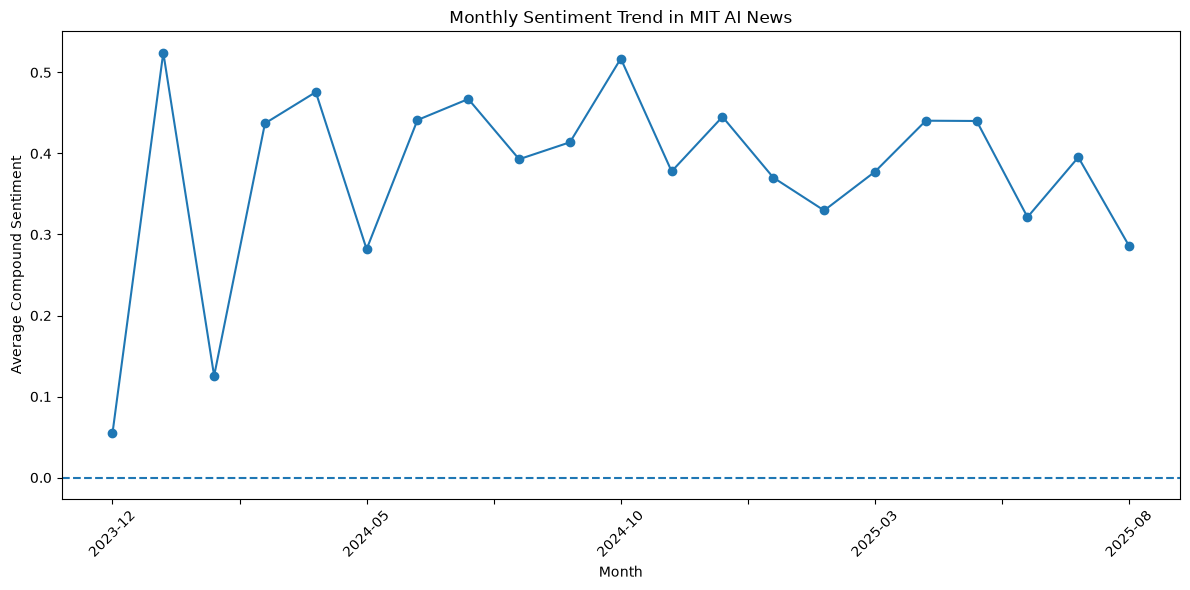

In [28]:
plt.figure(figsize=(12, 6))

monthly_sentiment.plot(
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title(
    "Monthly Sentiment Trend in MIT AI News"
)

plt.xlabel("Month")
plt.ylabel("Average Compound Sentiment")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [29]:
most_positive = (
    df[
        [
            "title",
            "publication_date",
            "summary",
            "compound"
        ]
    ]
    .sort_values(
        "compound",
        ascending=False
    )
    .head(10)
)

most_positive

Out[29]: 
                                                 title  ...  compound
193  Enhancing LLM collaboration for smarter, more ...  ...    0.9309
171  Artist and designer Es Devlin awarded Eugene M...  ...    0.9231
48   Envisioning a future where health care tech le...  ...    0.9201
40   Celebrating an academic-industry collaboration...  ...    0.9042
203  Helping robots practice skills independently t...  ...    0.9042
280  Researchers enhance peripheral vision in AI mo...  ...    0.9041
253  Natural language boosts LLM performance in cod...  ...    0.8979
28   New postdoctoral fellowship program to acceler...  ...    0.8979
198  AI assistant monitors teamwork to promote effe...  ...    0.8934
194  A fast and flexible approach to help doctors a...  ...    0.8934

[10 rows x 4 columns]


In [30]:
most_negative = (
    df[
        [
            "title",
            "publication_date",
            "summary",
            "compound"
        ]
    ]
    .sort_values(
        "compound",
        ascending=True
    )
    .head(10)
)

most_negative

Out[30]: 
                                                 title  ...  compound
248   From steel engineering to ovarian tumor research  ...   -0.7906
312  Using AI, MIT researchers identify a new class...  ...   -0.6908
231  Symposium highlights scale of mental health cr...  ...   -0.6369
149  Study: Browsing negative content online makes ...  ...   -0.6124
243                  2024 MAD Design Fellows announced  ...   -0.6037
170  Empowering systemic racism research at MIT and...  ...   -0.5423
59      Learning how to predict rare kinds of failures  ...   -0.5423
169  Despite its impressive output, generative AI d...  ...   -0.5271
282    Dealing with the limitations of our noisy world  ...   -0.4767
211  AI model identifies certain breast tumor stage...  ...   -0.4767

[10 rows x 4 columns]


In [31]:
df["title_sentiment"] = (
    df["title"]
    .apply(
        lambda x:
        sia.polarity_scores(str(x))["compound"]
    )
)

df["summary_sentiment"] = (
    df["summary"]
    .apply(
        lambda x:
        sia.polarity_scores(str(x))["compound"]
    )
)
print(
    "Average title sentiment:",
    df["title_sentiment"].mean()
)

print(
    "Average summary sentiment:",
    df["summary_sentiment"].mean()
)

Average title sentiment: 0.16342643312101912
Average summary sentiment: 0.28534363057324846


In [32]:
comparison = pd.DataFrame({
    "Text Type": ["Title", "Summary"],
    "Average Sentiment": [
        df["title_sentiment"].mean(),
        df["summary_sentiment"].mean()
    ]
})

comparison

Out[32]: 
  Text Type  Average Sentiment
0     Title           0.163426
1   Summary           0.285344


<ipython-input-33-a22fe04739df>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


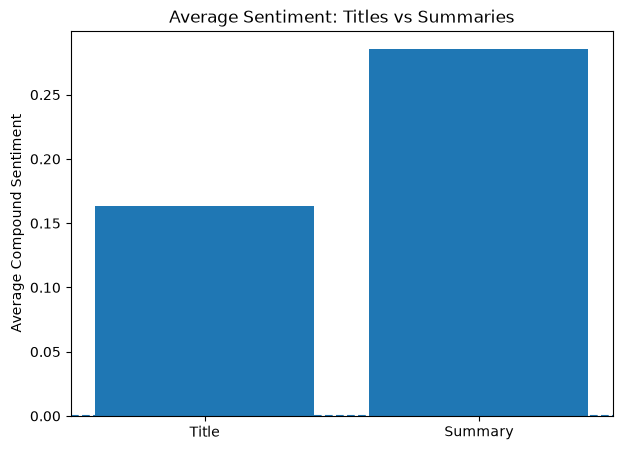

In [33]:
plt.figure(figsize=(7, 5))

plt.bar(
    comparison["Text Type"],
    comparison["Average Sentiment"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title(
    "Average Sentiment: Titles vs Summaries"
)

plt.ylabel("Average Compound Sentiment")

plt.show()

In [34]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = list(ENGLISH_STOP_WORDS)

In [35]:
positive_text = df.loc[
    df["sentiment"] == "Positive",
    "clean_text"
]

vectorizer_pos = CountVectorizer(
    stop_words=stop_words,
    max_features=20
)

X_pos = vectorizer_pos.fit_transform(
    positive_text
)

positive_keywords = pd.DataFrame({
    "keyword":
        vectorizer_pos.get_feature_names_out(),

    "frequency":
        X_pos.toarray().sum(axis=0)
})

positive_keywords = (
    positive_keywords
    .sort_values(
        "frequency",
        ascending=False
    )
)

positive_keywords

Out[35]: 
        keyword  frequency
0            ai        179
12          mit        115
15          new        100
17  researchers         57
14       models         56
1          data         46
6      language         44
4          help         42
13        model         41
8      learning         32
16     research         28
11       method         26
2    generative         25
18       robots         23
10      machine         23
3        health         23
7         large         21
19      systems         21
9          like         20
5       improve         18


In [36]:
negative_text = df.loc[
    df["sentiment"] == "Negative",
    "clean_text"
]

vectorizer_neg = CountVectorizer(
    stop_words=stop_words,
    max_features=20
)

X_neg = vectorizer_neg.fit_transform(
    negative_text
)

negative_keywords = pd.DataFrame({
    "keyword":
        vectorizer_neg.get_feature_names_out(),

    "frequency":
        X_neg.toarray().sum(axis=0)
})

negative_keywords = (
    negative_keywords
    .sort_values(
        "frequency",
        ascending=False
    )
)

negative_keywords

Out[36]: 
        keyword  frequency
0            ai         21
11          mit         17
16  researchers         16
14          new         13
13       models          9
9      learning          8
2          data          7
15     research          7
1        cancer          7
3        design          6
5        health          6
12        model          6
17        study          5
19        world          5
4     developed          5
8         large          4
7      language          4
6          help          4
18          way          4
10       mental          4


<ipython-input-37-6605294a4f4b>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


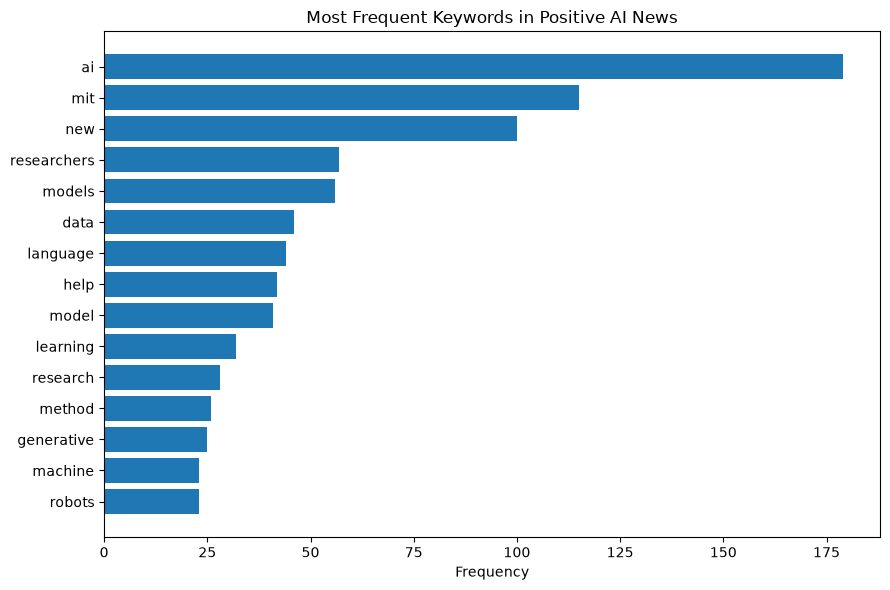

In [37]:
top_positive = (
    positive_keywords
    .head(15)
    .sort_values("frequency")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_positive["keyword"],
    top_positive["frequency"]
)

plt.title(
    "Most Frequent Keywords in Positive AI News"
)

plt.xlabel("Frequency")

plt.tight_layout()

plt.show()

<ipython-input-38-a692189fb1f0>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


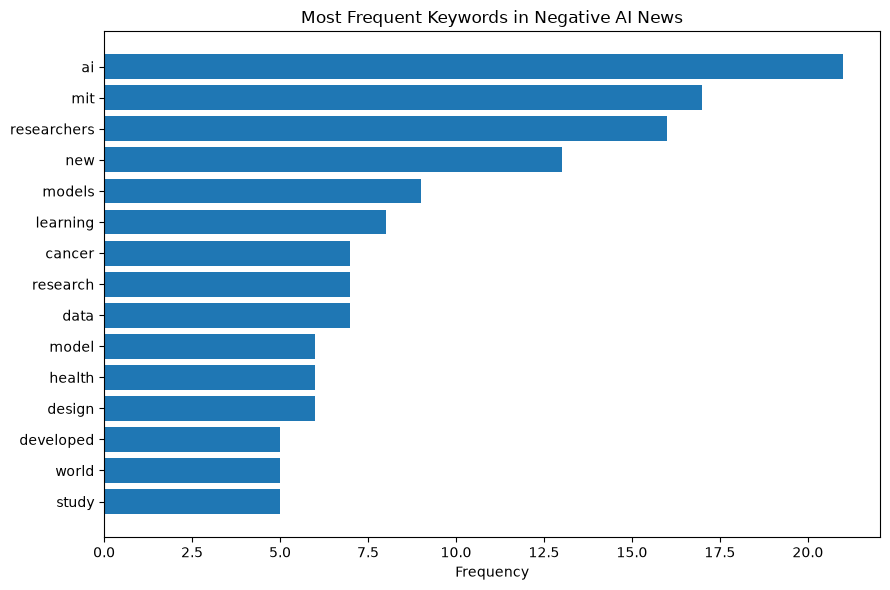

In [38]:
top_negative = (
    negative_keywords
    .head(15)
    .sort_values("frequency")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_negative["keyword"],
    top_negative["frequency"]
)

plt.title(
    "Most Frequent Keywords in Negative AI News"
)

plt.xlabel("Frequency")

plt.tight_layout()

plt.show()

In [39]:
bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=20
)

X_bigram = bigram_vectorizer.fit_transform(
    df["clean_text"]
)

bigram_df = pd.DataFrame({
    "bigram":
        bigram_vectorizer.get_feature_names_out(),

    "frequency":
        X_bigram.toarray().sum(axis=0)
})

bigram_df = (
    bigram_df
    .sort_values(
        "frequency",
        ascending=False
    )
)

bigram_df

Out[39]: 
                     bigram  frequency
7             generative ai         30
12         machine learning         29
9           language models         27
10           large language         22
3                 ai models         21
15          mit researchers         17
2                  ai model         16
6         csail researchers         13
8               health care         13
13                mit csail         13
5   artificial intelligence         11
18               new method         10
4                ai systems          8
11           learning model          8
17             new approach          8
16                   new ai          7
0                 ai agents          7
14            mit engineers          7
1                    ai mit          7
19                 using ai          7


In [40]:
# Install dependencies using requirements.txt before running this notebook.


In [41]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [42]:
positive_text = " ".join(
    df.loc[df["sentiment"] == "Positive", "clean_text"]
)

negative_text = " ".join(
    df.loc[df["sentiment"] == "Negative", "clean_text"]
)

In [43]:
custom_stopwords = set(ENGLISH_STOP_WORDS)
custom_stopwords.update([
    "ai",
    "artificial",
    "intelligence",
    "mit",
    
    "model",
    "models",
    "data",
    "learning",
    "machine",
    "language",
    
    "research",
    "researcher",
    "researchers",
    "study",
    "studies",
    
    "method",
    "methods",
    "system",
    "systems",
    
    "new",
    "using",
    "use",
    "used",
    "work",
    "works",
    
    "develop",
    "developed",
    "technology",
    "technologies"
])

<ipython-input-44-e3154f9f7405>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


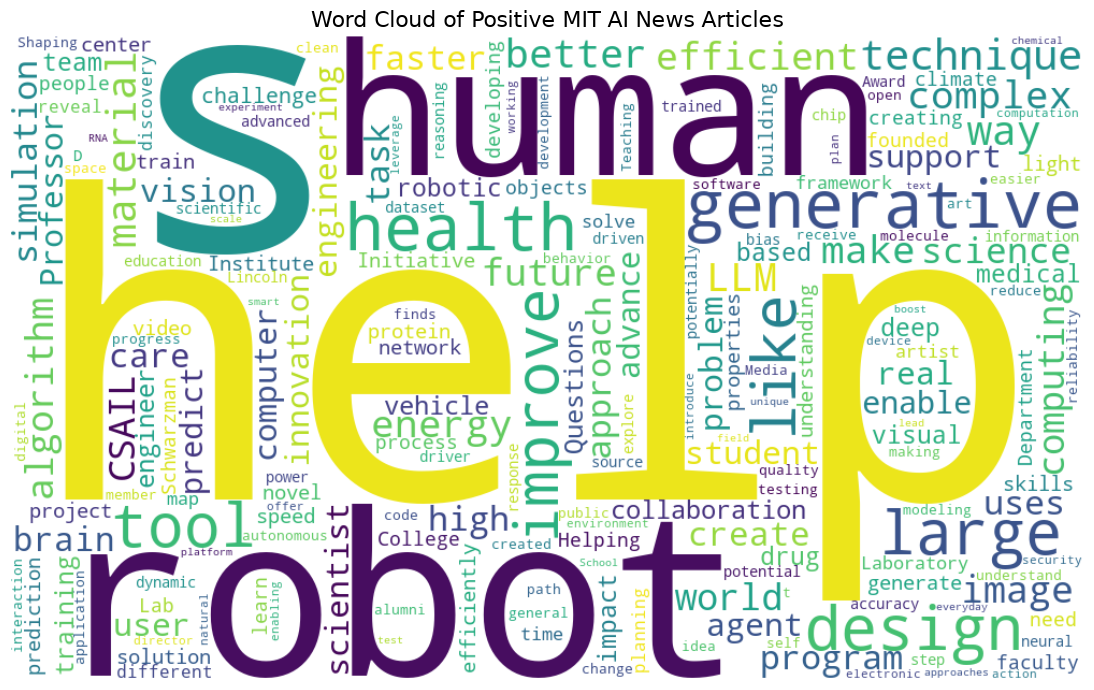

In [44]:
positive_wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color="white",
    stopwords=custom_stopwords,
    collocations=False
).generate(positive_text)

plt.figure(figsize=(12, 7))

plt.imshow(
    positive_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Word Cloud of Positive MIT AI News Articles",
    fontsize=16
)

plt.tight_layout()

plt.show()

<ipython-input-45-1d906c61bcf3>:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


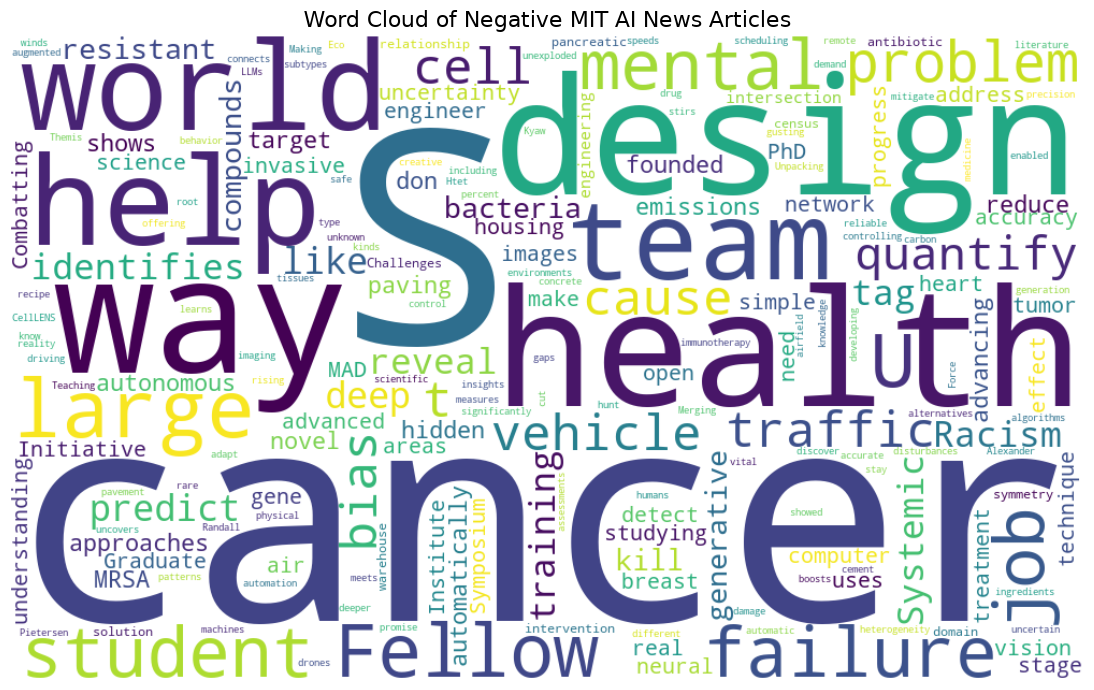

In [45]:
negative_wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color="white",
    stopwords=custom_stopwords,
    collocations=False
).generate(negative_text)

plt.figure(figsize=(12, 7))

plt.imshow(
    negative_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title(
    "Word Cloud of Negative MIT AI News Articles",
    fontsize=16
)

plt.tight_layout()

plt.show()

<ipython-input-46-f0aff277300f>:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


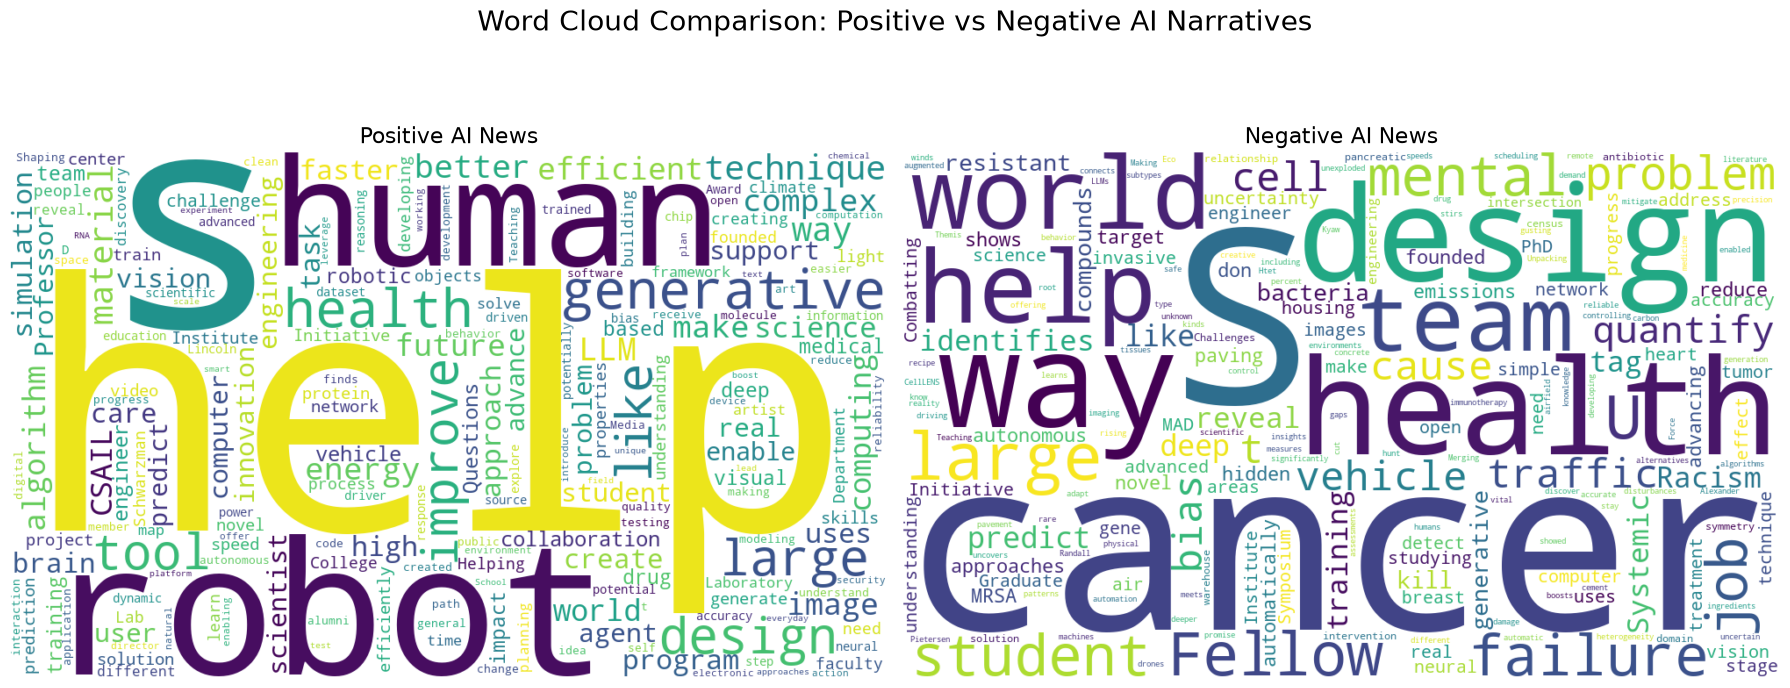

In [46]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 8)
)

axes[0].imshow(
    positive_wordcloud,
    interpolation="bilinear"
)

axes[0].axis("off")

axes[0].set_title(
    "Positive AI News",
    fontsize=16
)


axes[1].imshow(
    negative_wordcloud,
    interpolation="bilinear"
)

axes[1].axis("off")

axes[1].set_title(
    "Negative AI News",
    fontsize=16
)

plt.suptitle(
    "Word Cloud Comparison: Positive vs Negative AI Narratives",
    fontsize=20
)

plt.tight_layout()

plt.show()